In [1]:
import csv
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.phase_velocity import vNtoQ_Pc

In [6]:
Pc = [1e8, 1.5e8, 2e8, 2.5e8, 3e8]
ve = []
B = []

for PP in Pc:
    ve_tmp, B_tmp = vNtoQ_Pc(
        T = 5,                     # temperature in MeV
        P_crit = PP,              # transition pressure in MeV^4
        DelP = 1e7,                # measures how far from equilibrium; this can't be determined from bag constant
        m_s = 90,                  # strange quark mass
        param = para.paraQMCRMF3,  # RMF model for nuclear matter
        NM_type = "PNM",           # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
        method = "numerical"
    )
    ve.append(ve_tmp)
    B.append(B_tmp)

/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and

In [10]:
# Combine them as columns (row by row)
rows = zip(ve, B, Pc)

# Write to CSV with an empty first row
with open('output.csv', mode='w', newline='') as file:
    writer = csv.writer(file)
    
    # Write empty first row (2 empty cells)
    writer.writerow(["velocity (m/s)", "bag constant^1/4 (MeV)", "critical P (MeV^4)"])
    
    # Write the data rows
    writer.writerows(rows)

    writer.writerow(["", "", ""])
    writer.writerow(["T = 5 MeV", "DeltaP = 1e7 MeV^4", "m_s = 90 MeV", "alpha_s = 0.3", "mass of u, d, e = 0"])
   # writer.writerow(["in MeV^x"])

In [4]:
ve, B, Pc

([np.float64(5.463699647816916),
  np.float64(4.706187376863701),
  np.float64(4.337581216711517),
  np.float64(4.138840217155054),
  np.float64(4.031528972526389)],
 [np.float64(170.96069633828),
  np.float64(172.8845039715705),
  np.float64(174.57197160302394),
  np.float64(176.12521258128913),
  np.float64(177.59497568832967)],
 [100000000.0, 150000000.0, 200000000.0, 250000000.0, 300000000.0])

In [2]:
ve_tmp, B_tmp = vNtoQ_Pc(
    T = 5,                     # temperature in MeV
    P_crit = 1e8,              # transition pressure in MeV^4
    DelP = 1e6,                # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 90,                  # strange quark mass
    param = para.paraQMCRMF3,  # RMF model for nuclear matter
    NM_type = "PNM",           # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "numerical"
)

ve_tmp, B_tmp

/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


(np.float64(5.463699647816916), np.float64(170.96069633828))

In [22]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

n0 = 0.16 * const.MeV_fm**3

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 5*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 75, int(N*3/5))])
DD = np.linspace(0.01*nc, 0.1*nc, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("Deln_T_ncrit="+str(nc/n0)+".npy", V)

0 0 407.65302859006226
0 1 563.0031019067889
0 2 734.2887249171717
0 3 923.7619426145411
0 4 1134.9677579197405
0 5 1372.5109754563684
0 6 1643.0708282893656
0 7 1956.646882247077
0 8 2327.9929299176074
0 9 2780.8807786022962
0 10 3358.36900170139
0 11 4143.160601307162
0 12 5333.612161818739
0 13 7582.53079605754
0 14 16647.62903480751
0 15 11801.833867566738
0 16 7986.019372965749
0 17 6682.977045594576
0 18 6004.860911593953
0 19 5592.782822159198
0 20 5318.965781445186
0 21 5127.872564187434
0 22 4990.482701290474
0 23 4889.709953065573
0 24 4815.464817826176
0 25 4760.499820735177
0 26 4720.041003806222
0 27 4691.148022565248
0 28 4671.554255770975
0 29 4658.830042183105
1 0 181.16370162283812
1 1 247.13244268926596
1 2 319.8027306371096
1 3 400.16053459341276
1 4 489.69058663623514
1 5 590.4668738041443
1 6 705.2521760456136
1 7 838.1632173123348
1 8 995.5915621903413
1 9 1187.7817805967034
1 10 1432.9421847194371
1 11 1766.520037955933
1 12 2273.435372171355
1 13 3232.7913107537

/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:690: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  muB_N = fsolve(PNM_minus_PShift, 1050)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:306: RuntimeWarning: invalid value encountered in sqrt
  vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * np.abs(aN - aQstar)))) * 3e8


16 11 nan
16 12 764.7892996453929
16 13 1587.2917230725982
16 14 1186.646428403448
16 15 777.9411448661878
16 16 637.8291509484122
16 17 563.4375458349555
16 18 516.5451666042864
16 19 484.2215845477374
16 20 460.5055234347067
16 21 442.4761893737553
16 22 428.31790877320014
16 23 416.9637473964392
16 24 407.72654842110535
16 25 400.08453114056124
16 26 393.7055190413085
16 27 388.31872678825334
16 28 383.7701890873574
16 29 379.88268966910516
17 0 91.16617780369532
17 1 111.51480230963263
17 2 132.50694718001617
17 3 154.78029844153758
17 4 178.97639957739463
17 5 205.865276022359
17 6 236.5605748587374
17 7 272.60247677927526
17 8 316.57675204538003
17 9 372.94208107142083
17 10 450.82091322561394


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:690: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  muB_N = fsolve(PNM_minus_PShift, 1050)[0]
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:306: RuntimeWarning: invalid value encountered in sqrt
  vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * np.abs(aN - aQstar)))) * 3e8


17 11 nan
17 12 818.56961337709
17 13 2329.4113855217847
17 14 1040.8183920948577
17 15 731.9470823677631
17 16 611.2957821900404
17 17 544.4390101418248
17 18 501.3967458415235
17 19 471.26991866538486
17 20 448.9913982594945
17 21 431.88147238659843
17 22 418.37093173858193
17 23 407.49605066141794
17 24 398.57211317816376
17 25 391.1670883757634
17 26 384.95471341883206
17 27 379.68761568552554
17 28 375.20268122692374
17 29 371.35261694415004
18 0 92.30120156335079
18 1 112.88050134956488
18 2 134.12314744413834
18 3 156.6845083805686
18 4 181.24881438921943
18 5 208.60811279327805
18 6 239.93561257989398
18 7 276.94080754238774
18 8 322.396025807224
18 9 381.39439605294484
18 10 464.3871366657347


...

29 9 480.43450380264215


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:690: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  muB_N = fsolve(PNM_minus_PShift, 1050)[0]


29 10 301.12784473668745


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:690: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  muB_N = fsolve(PNM_minus_PShift, 1050)[0]


29 11 302.02872068346636
29 12 0.008669221710775827
29 13 0.025622104475402113
29 14 0.008405132160113413
29 15 0.01656160425273768
29 16 0.0
29 17 0.00808365974283808
29 18 387.56029620919384
29 19 375.40709322935317
29 20 365.56684662908503
29 21 357.4581342500221
29 22 350.66533771602616
29 23 344.90445975648737
29 24 339.97749984344944
29 25 335.7145955361238
29 26 331.99663356972013
29 27 328.7497465396738
29 28 325.87693787146924
29 29 323.33262237250506


Text(0, 0.5, 'T  (MeV)')

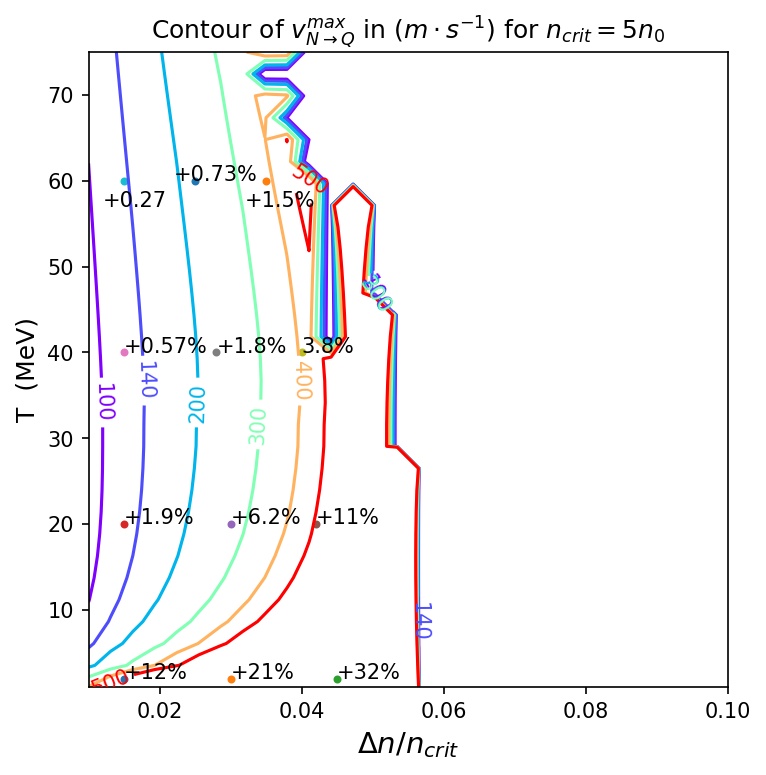

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import RMFsolver.constants as const

n0 = 0.16 * const.MeV_fm**3

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
#T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

V_old = np.load("/Users/janshao/Documents/GRAD_STUDY/Research/Dense_Matter/7_Aug_2025/Deln=0.1ncrit/Deln_T_ncrit=5.0.npy")
D_grid_old, T_grid_old = np.meshgrid(np.linspace(0.01, 0.1, 30), np.linspace(1, 75, 30))

contours = plt.contour(D_grid_old, T_grid_old, V_old, levels = np.array([100, 140, 200, 300, 400, 500]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

siz = 8

plt.scatter(0.015, 2, s=siz)
plt.text(0.015, 2, "+12%") # 1.121192
plt.scatter(0.030, 2, s=siz)
plt.text(0.030, 2, "+21%") # 1.2123
plt.scatter(0.045, 2, s=siz)
plt.text(0.045, 2, "+32%") # 1.3180

plt.scatter(0.015, 20, s=siz)
plt.text(0.015, 20, "+1.9%")
plt.scatter(0.030, 20, s=siz)
plt.text(0.030, 20, "+6.2%")
plt.scatter(0.042, 20, s=siz)
plt.text(0.042, 20, "+11%")

plt.scatter(0.015, 40, s=siz)
plt.text(0.015, 40, "+0.57%") # 1.0056665
plt.scatter(0.028, 40, s=siz)
plt.text(0.028, 40, "+1.8%") # 1.018145
plt.scatter(0.040, 40, s=siz)
plt.text(0.040, 40, "3.8%") # 1.0381105

plt.scatter(0.015, 60, s=siz)
plt.text(0.012, 57, "+0.27") # 1.002737
plt.scatter(0.025, 60, s=siz)
plt.text(0.022, 60, "+0.73%") # 1.0072912
plt.scatter(0.035, 60, s=siz)
plt.text(0.032, 57, "+1.5%") # 1.0149815




plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=5n_0$" )
plt.xlabel(r"$\Delta n / n_{crit}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

In [3]:
V.min(), V.max()

(np.float64(4.895900490806852), np.float64(168.9106809399307))

In [63]:
-np.ones(4)

array([-1., -1., -1., -1.])

In [29]:
import numpy as np
from scipy.integrate import solve_bvp
import matplotlib.pyplot as plt

# --- Constants ---
T       = 8.0
muQ     = 524.0
aQ      = 0.29       # a_Q^*
aN      = 0.42
alpha_s = 0.3
L       = aQ         # L = aQ
v_input = 2.3497050233918824e-7  # to test

# --- Microphysics ---
g_s  = np.sqrt(4 * np.pi * alpha_s)
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300.0 / muQ)**5)

qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h    = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

# κ(v) from the linearized tail (NOTE: ηQ appears under the radical)
def get_kappa(v):
    return 2.0 * DQ / (-v + np.sqrt(v*v + 4.0 * DQ * etaQ / tauQ))

# Nonlinearity
def R(a):
    return (a**3 + etaQ * a) / tauQ

# ---------- Correct mapped ODE ----------
# State: y[0] = a(t), y[1] = p(t) = da/dx  (physical slope)
# Mapping: t = c1(1 - e^{-x/κ})  =>  dx/dt = κ/(c1 - t)
def ode_system(t, y, v, kappa):
    tmp = ( R(y[0]) + (DQ * ((L-t)/kappa**2) + v * ((L-t)/kappa))*y[1] ) / (DQ * ((L-t)/kappa))
    return np.vstack((y[1], tmp))

# Boundary conditions: a(0) = aQ, a(c1) = 0
def bc(ya, yb):
    return np.array([ya[0] - aQ, yb[0]])

def get_derivatives_at_zero(v, return_solution=False, plot=False, verb=False):
    kappa = get_kappa(v)
    NN = 1000
    t = np.linspace(0, L - 1e-8, NN)

    # Initial guess: smooth, monotone
    a_guess = aQ - t
    a_t_guess = -np.ones(NN)
    y_init  = np.vstack((a_guess, a_t_guess))

    try:
        sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa), bc, t, y_init, max_nodes=100000)
        if sol.status != 0:
            raise RuntimeError("solve_bvp failed")

        a_prime_t0 = sol.y[1, 0]
        a_prime_x0 = a_prime_t0 * ( (L) / kappa )

        if verb:
            print(f" v = {v:.3e}")
            print(f"a'(t=0) = {a_prime_t0:.4e}")
            print(f"a'(x=0) = {a_prime_x0:.4e}")

        if plot:
            # a(t)
            plt.figure(figsize=(10, 4))
            plt.subplot(1, 2, 1)
            plt.plot(sol.x, sol.y[0])
            plt.xlabel(r"$t$")
            plt.ylabel(r"$a(t)$")
            plt.title("Profile in Transformed Space")
            plt.grid()

            # a(x) on the mapped mesh (stable)
            t_plot = sol.x
            x_plot = -kappa * np.log(1.0 - t_plot / L)
            plt.subplot(1, 2, 2)
            plt.plot(x_plot, sol.y[0])
            plt.xlabel(r"$x$")
            plt.ylabel(r"$a(x)$")
            plt.title("Profile in Physical Space")
            plt.grid()

            plt.tight_layout()
            plt.show()

        if return_solution:
            return a_prime_x0, a_prime_t0, sol
        else:
            return a_prime_x0, a_prime_t0

    except Exception as e:
        if verb:
            print(f"Solver failed for v = {v:.2e}: {e}")
        return None, None

 v = 3.333e-08
a'(t=0) = -1.0000e+00
a'(x=0) = -1.1624e-07


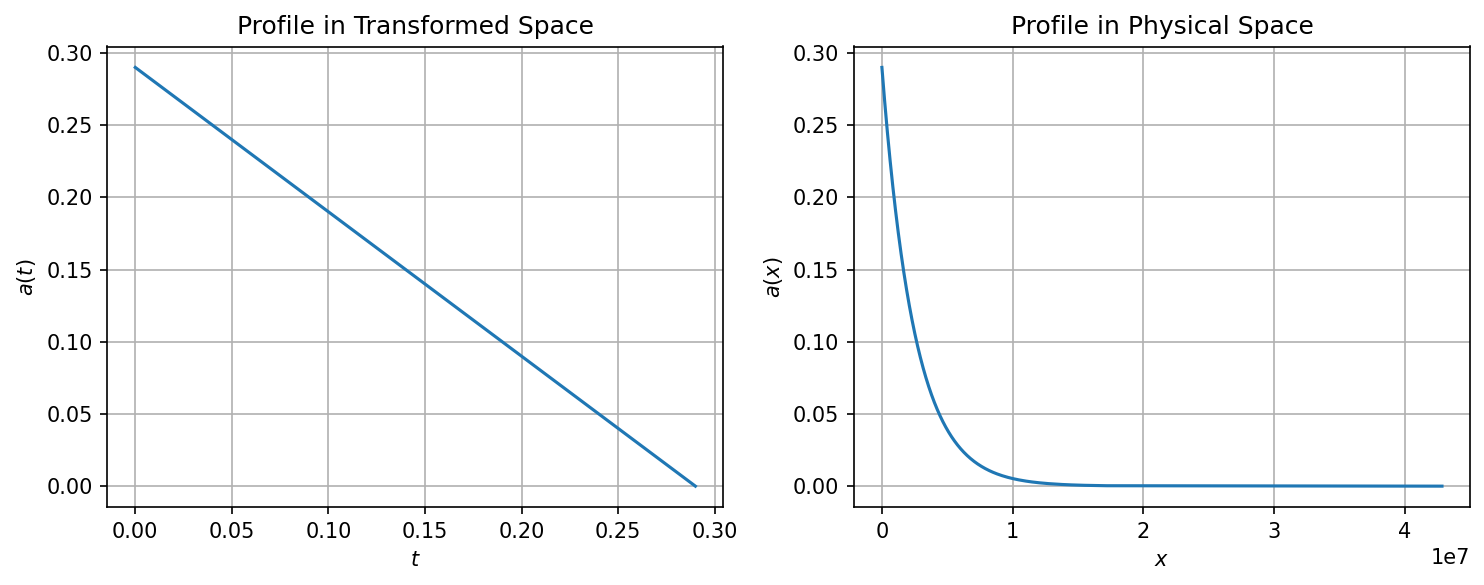

In [30]:
# new
a_prime_x0, a_prime_xtilde0, sol = get_derivatives_at_zero(v= 10 / 3e8, return_solution=True, plot=True, verb=True)

🎯 Converged: v = 5.052756462276e-07
 v = 5.053e-07
a'(t=0) = -1.0000e+00
a'(x=0) = -6.7369e-08


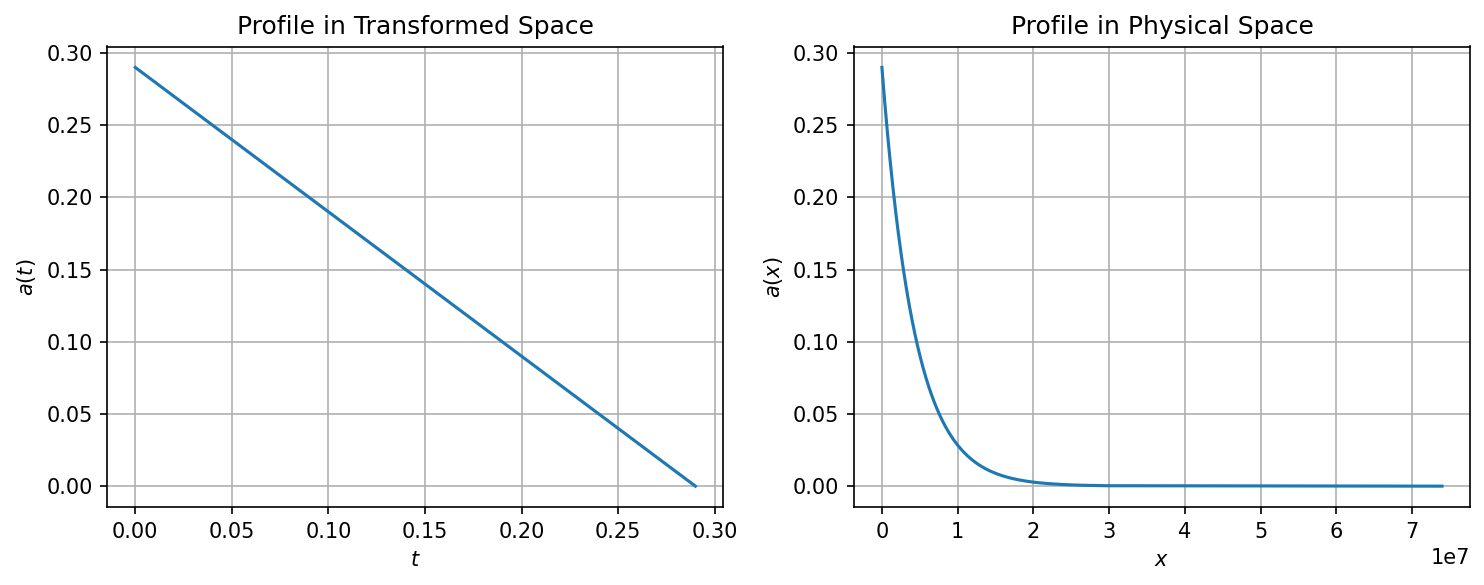

In [31]:
# new
from scipy.optimize import root

def slope_residual(v_arr):
    v = float(np.abs(v_arr[0]))  # ✅ extract scalar from array
    a_prime_x0, _ = get_derivatives_at_zero(v)
    if a_prime_x0 is None:
        return np.inf  # large penalty on failure
    rhs = -v * (aN - aQ) / DQ  # ✅ correct sign (check this is your definition)
    return a_prime_x0 - rhs

# --- Root solve ---
v_guess = 1e-7
sol = root(slope_residual, [v_guess], method='hybr')

if sol.success:
    v_root = float(np.abs(sol.x[0]))
    print(f"🎯 Converged: v = {v_root:.12e}")
    get_derivatives_at_zero(v_root, plot=True, verb=True)
else:
    raise RuntimeError(f"❌ Root finding failed: {sol.message}")

In [32]:
import numpy as np
from scipy.integrate import solve_bvp
from scipy.optimize import root

def _vNtoQ_num(T, aQstar, aN, muQ):
    alpha_s = 0.3
    L = aQstar

    # --- microphysics ---
    g_s  = np.sqrt(4*np.pi*alpha_s)
    etaQ = (9*np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300.0 / muQ)**5)

    qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h    = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    # κ(v) from the linearized tail (η_Q must be present!)
    def get_kappa(v):
        return 2 * DQ / (-v + np.sqrt(v*v + 4 * DQ * etaQ / tauQ))

    # Nonlinearity
    def R(a):
        return (a**3 + etaQ * a) / tauQ

    # ODE in t = \tilde{x}: y[0]=a(t), y[1]=p(t)=da/dx
    def ode_system(t, y, v, kappa):
        tmp = ( R(y[0]) + (DQ * ((L-t)/kappa**2) + v * ((L-t)/kappa))*y[1] ) / (DQ * ((L-t)/kappa))
        return np.vstack((y[1], tmp))

    # Boundary conditions: a(0)=aQ*, a(c1)=0
    def bc(ya, yb):
        return np.array([ya[0] - aQstar, yb[0]])

    # Solve BVP for a given v and return a'(x=0)=p(0)
    def get_derivatives_at_zero(v):
        v = float(abs(v))
        kappa = get_kappa(v)
        t = np.linspace(0, L - 1e-8, 1000)

        # Smooth monotone initial guess
        a_guess = aQstar - t
        a_t_guess = -np.ones(1000)
        y_init  = np.vstack((a_guess, a_t_guess))

        try:
            sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa),
                            bc, t, y_init, max_nodes=100000)
            if sol.status != 0:
                return None
            return sol.y[1, 0] * L / kappa   # p(0) = a'(x=0)
        except Exception:
            return None

    # Residual for remaining BC at x=0: a'(0+) = - v (aN - aQ*) / DQ
    def slope_residual(v_arr):
        v = float(abs(v_arr[0]))          # root() passes arrays
        a_prime_x0 = get_derivatives_at_zero(v)
        if a_prime_x0 is None or not np.isfinite(a_prime_x0):
            return 1e20                   # penalize failed BVP
        rhs = -v * (aN - aQstar) / DQ
        return a_prime_x0 - rhs

    # Solve for v (natural units), then convert to m/s for backward compatibility
    sol = root(slope_residual, [1e-7], method='hybr')
    if sol.success and sol.x[0] > 0:
        v_nat = float(abs(sol.x[0]))      # c = 1 units
        return v_nat * 3e8                # return m/s as your original code did
    else:
        raise RuntimeError(f"Root finding failed: {sol.message}")

In [33]:
# new
_vNtoQ_num(T = 8, aQstar = 0.29, aN = 0.42, muQ = 524) 

151.5826938682735

In [34]:
# example sweep (returns v in natural units; convert to m/s in the plot)
muQ = 300.0
aN  = 0.8
aQ_vals = np.linspace(0.01, 0.49, 30)
T_vals  = np.hstack([np.linspace(1, 10, 12), np.linspace(11, 60, 8)])

AQS, TT = np.meshgrid(aQ_vals, T_vals)
V = np.full_like(AQS, np.nan, dtype=float)

for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        try:
            v_nat = _vNtoQ_num(TT[i, j], AQS[i, j], aN, muQ)
            V[i, j] = v_nat  # convert once to m/s
            print(i,j)
        except Exception:
            pass

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
0 25
0 26
0 27
0 28
0 29
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24
1 25
1 26
1 27
1 28
1 29
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18
2 19
2 20
2 21
2 22
2 23
2 24
2 25
2 26
2 27
2 28
2 29
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
3 8
3 9
3 10
3 11
3 12
3 13
3 14
3 15
3 16
3 17
3 18
3 19
3 20
3 21
3 22
3 23
3 24
3 25
3 26
3 27
3 28
3 29
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
4 8
4 9
4 10
4 11
4 12
4 13
4 14
4 15
4 16
4 17
4 18
4 19
4 20
4 21
4 22
4 23
4 24
4 25
4 26
4 27
4 28
4 29
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
5 8
5 9
5 10
5 11
5 12
5 13
5 14
5 15
5 16
5 17
5 18
5 19
5 20
5 21
5 22
5 23
5 24
5 25
5 26
5 27
5 28
5 29
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
6 20
6 21
6 22
6 23
6 24
6 25
6 26
6 27
6 28
6 29
7 0
7 1
7 2
7 3
7 4


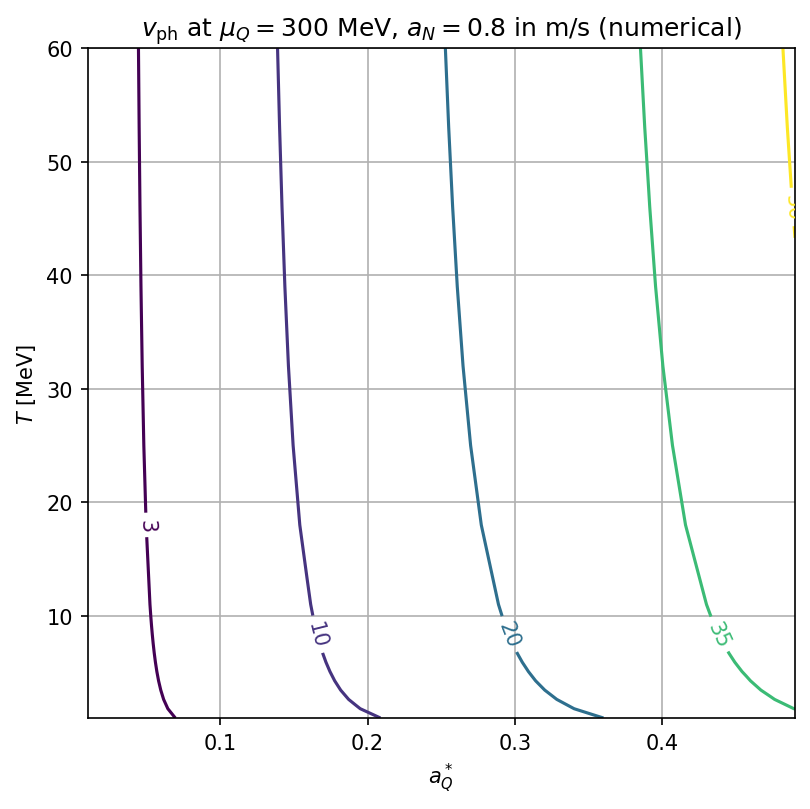

In [35]:
import matplotlib.pyplot as plt
levels = [3,10,20,35,50]
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150
cs = plt.contour(AQS, TT, V, levels=levels)
plt.clabel(cs, fmt='%d')
plt.xlabel(r"$a_Q^*$")
plt.ylabel(r"$T$ [MeV]")
plt.title(r"$v_{\rm ph}$ at $\mu_Q=300$ MeV, $a_N=0.8$ in m/s (numerical)")
plt.grid(True); plt.tight_layout(); plt.show()
#plt.savefig("1.pdf")

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

def Get_Two_as(T, n_crit, Deln, m_s, param, NM_type, method):
    '''
    Computes NM to SQM phase boundary velocity 

    Parameters:
    - T        : temperature
    - n_crit   : critical density for 1st order phase transition
    - Deln     : Messures how far away from equilibrium
    - m_s      : strange quark mass
    - param    : mean field theory model settings for nuclear matter
    - NM_type  : assumptions for nuclear matter, choose from:
                 - "Beta_eq" for beta equilibriated nuclear matter
                 - "PNM" for pure neutron matter
                 - "SYM" for symmetric nuclear matter
    - method   : ways to calculate velocity
                 - "numerical" in principle more precise, but have numerical noise
                 - "analytical" analytical approximation, direct, faster, and robust, ~ 10% difference with numerical method

    Returns:
    - velocity of phase boundary in meters per second
    '''

    def PNM(mu_B, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")


    def PNM_n(nB, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")
  

    # solve for bag constant
    P_crit = PNM_n(n_crit, T)
    P_diff = lambda x: PNM(x, T) - P_crit
    muB_crit = fsolve(P_diff, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
    B_SQM = fsolve(PQM_solve_for_B, 180)[0]

    # solve for points Q and N at beta eq.
    DelP = PNM_n(n_crit + Deln, T) - P_crit
    PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]

    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

    # calculating aQstar
    if method == "numerical":
        epsilon = np.sqrt(np.finfo(float).eps)
        muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
        PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
        grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
        nB_Qstar = grad_Qstar[0]
        nK_Qstar = grad_Qstar[1]
        grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
        nB_Q = grad_Q[0]
        nK_Q = grad_Q[1]
        aQstar = (nK_Qstar - nK_Q)/nB_Q  
 
    elif method == "analytical":
        PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
        PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
        ddPQM_ddmuK = Derivative(PQM_muK, n=2)
        dPQM_dmuK = Derivative(PQM_muK, n=1)
        dPQM_dmuB = Derivative(PQM_muB, n=1)
        chiK_Q = ddPQM_ddmuK(0)
        nB_Q = dPQM_dmuB(muB_Q)
        nK_Q = dPQM_dmuK(0)
        aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
        muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
        PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
        muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

    else:
        raise RuntimeError(f"Input method unknown")
        return None

    # calculating aN
    PNM_wrap = lambda x: PNM(x, T)
    dPNM_dmuB = Derivative(PNM_wrap, n=1)
    nB_N = dPNM_dmuB(muB_N)
    aN = (nB_N - nK_Q) / nB_Q   

    return aQstar, aN

In [5]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 4*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

a_diff = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        aQ_tmp, aN_tmp = Get_Two_as(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        a_diff[i,j] = aN_tmp - aQ_tmp
        print(i, j, a_diff[i,j])

#np.save("aQstar_aN_n_crit="+str(nc/n0)+".npy", a_diff)

0 0 0.4254797476330998
0 1 0.3749938334124293
0 2 0.3395605974983571
0 3 0.3107190886006196
0 4 0.2858426735386399
0 5 0.26368828996226135
0 6 0.24356463584314175
0 7 0.2250277352554888
0 8 0.20776171047508485
0 9 0.19156121273279658
0 10 0.1762811395289401
0 11 0.161772192281195
0 12 0.14796111111405885
0 13 0.13474998045665204
0 14 0.12207456393383664
0 15 0.10990154622046294
0 16 0.09816518311233191
0 17 0.08684199080798338
0 18 0.07588365921307666
0 19 0.06527481829104692
0 20 0.05497670955308637
0 21 0.04497629065474623
0 22 0.0352531105283343
0 23 0.02579260190650956
0 24 0.016566922519924032
0 25 0.007573270634335327
0 26 -0.0012083754893560394
0 27 -0.009782948686575699
0 28 -0.018161200388926657
0 29 -0.026359586229861343
1 0 0.42534891597960567
1 1 0.3748697224290615
1 2 0.3394398373419926
1 3 0.31060138035077217
1 4 0.28571296196152074
1 5 0.2635619619001234
1 6 0.2434419180091268
1 7 0.22488187599466614
1 8 0.20762933938314226
1 9 0.19144512570743805
1 10 0.1761534831670830

/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  result, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the int

5 10 0.17451435616981387
5 11 0.16001141901245375
5 12 0.14619680706620297
5 13 0.13299569361849783
5 14 0.12032899268270675
5 15 0.10816214873261687
5 16 0.09643236192377125
5 17 0.08511461115237517
5 18 0.0741611527143235
5 19 0.06354770209611793
5 20 0.053265758562468346
5 21 0.04327370182341139
5 22 0.03355208108589869
5 23 0.024090691908443596
5 24 0.014874615321124662
5 25 0.005890100055248149
5 26 -0.002880418715316968
5 27 -0.011453493669519865
5 28 -0.019830843330766124
5 29 -0.028020798660171042
6 0 0.42297768119437684
6 1 0.37250429938405194
6 2 0.33706668605379175
6 3 0.30822435074038845
6 4 0.28335659433677796
6 5 0.26120653100412683
6 6 0.24108145608480264
6 7 0.222544896059708
6 8 0.2052899177816342
6 9 0.18909701201252976
6 10 0.17382000607348885
6 11 0.15932334500831596
6 12 0.14551035264145823
6 13 0.13230833987303053
6 14 0.11964840185762099
6 15 0.10748540871600065
6 16 0.09575222120947285
6 17 0.08443231743866486
6 18 0.07348494517518755
6 19 0.0628781693799107
6 2

Text(0, 0.5, 'T  (MeV)')

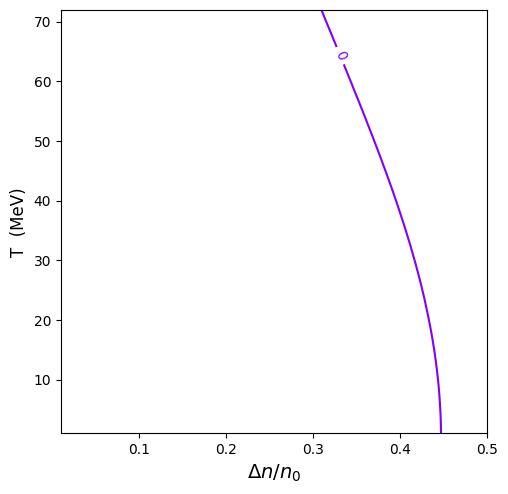

In [6]:
T_grid, D_grid = np.meshgrid(TT, DD)

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting


#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/n0, T_grid, a_diff.T, levels = [0], cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

#plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{0}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

(1.0, 72.0)

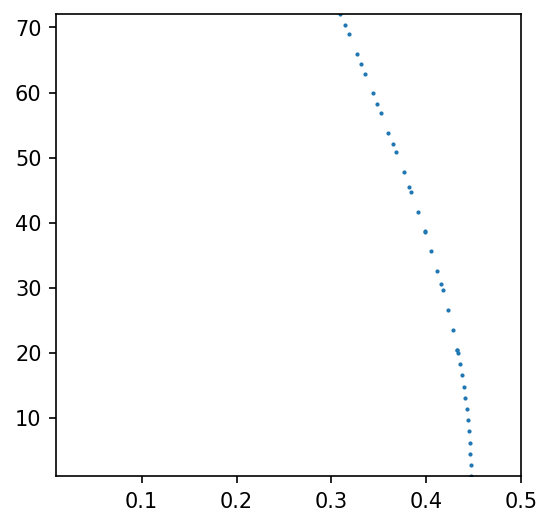

In [12]:
from RMFsolver.phase_velocity import extract_contour_coords_num
Deln_cut, T_cut = extract_contour_coords_num(D_grid, T_grid, a_diff.T, level=0)

plt.figure(figsize=[4,4])
plt.scatter(Deln_cut/n0, T_cut, s=1)
plt.xlim(0.01, 0.5)
plt.ylim(1, 72)

0.43912829479645704


(1.0, 72.0)

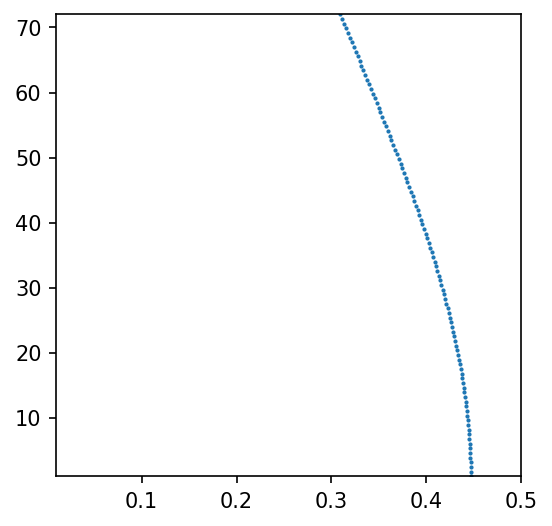

In [16]:
import numpy as np
from scipy.interpolate import interp1d

# Suppose your arrays are:
# Deln_cut = np.array([...])   # x values
# T_cut = np.array([...])      # y values

# Define interpolation function: x = f(y)
Cut = interp1d(T_cut, Deln_cut, kind='linear', fill_value="extrapolate")

print(Cut(15)/n0)

# Example usage:
Tempr = np.linspace(1, 72, 100)
Del = np.array([Cut(Tempr[i]) for i in range(len(Tempr))])

plt.figure(figsize=[4,4])
plt.scatter(Del/n0, Tempr, s=1)
plt.xlim(0.01, 0.5)
plt.ylim(1, 72)

In [22]:
#np.save("Shade_n_crit="+str(nc/n0)+".npy", np.array([Deln_cut, T_cut]))

In [20]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 4*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
#DD = np.linspace(0.01*n0, 0.5*n0, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    DD = np.linspace(0.01*n0, np.minimum(0.5*n0, Cut(TT[i])-0.015*n0), N)
    for j in range(N):  # loop over B (columns)
        V[i,j], _ = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("v_n_crit="+str(nc/n0)+".npy", V)

0 0 36.3036893503639
0 1 90.59735561168878
0 2 148.87559529554224
0 3 210.87031155955424
0 4 276.5177081227038
0 5 345.9376768420097
0 6 419.22565352155283
0 7 496.6847291074933
0 8 578.5321159990009
0 9 665.2024632190892
0 10 757.0974997794353
0 11 854.8249557490676
0 12 958.9265402994102
0 13 1070.2184406332617
0 14 1189.68388604076
0 15 1318.568193802669
0 16 1458.2667646504815
0 17 1610.6375634436702
0 18 1777.972820977479
0 19 1963.4079912829693
0 20 2171.2331614421682
0 21 2406.882852643738
0 22 2678.4108821266414
0 23 2997.796382080426
0 24 3383.333351046668
0 25 3864.38377968806
0 26 4496.947456783558
0 27 5393.721235822534
0 28 6843.734148076681
0 29 9962.440644415672
1 0 20.201159237185422
1 1 43.88411594004638
1 2 68.8048439285491
1 3 95.17019645294891
1 4 123.03718800007296
1 5 152.4511250175414
1 6 183.48592304454507
1 7 216.26431446075384
1 8 250.89980698084324
1 9 287.55092275734194
1 10 326.44661174161075
1 11 367.732507520039
1 12 411.7446445341933
1 13 458.84885666165

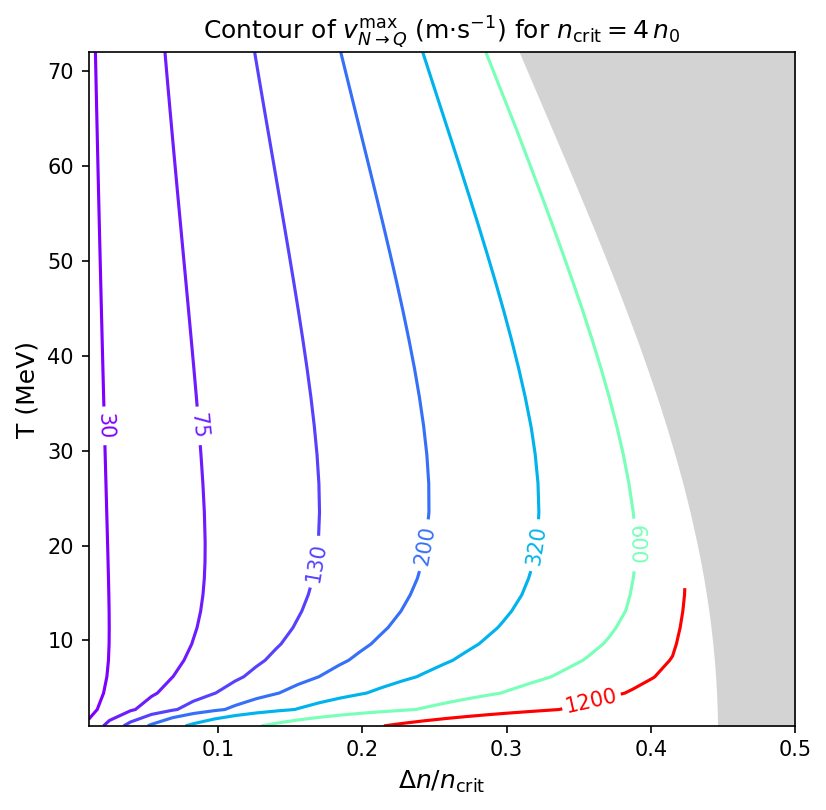

In [35]:
#np.array([25, 40, 55, 70, 90, 115, 150, 200])
# Inputs you already have:
# TT: (N,) temperatures
# V : (N, N) values with V[i, j] corresponding to (TT[i], DD[i, j])
# n0, nc, Cut: given in your code
N = len(TT)

# --- build the irregular structured grid ---
# along-row parameter (0..1) for each density sample
t = np.linspace(0.0, 1.0, N)

# upper bound for Δn at each TT[i]
Dmax = np.minimum(0.5 * n0, Cut(TT) - 0.015 * n0)           # shape (N,)

# ensure the upper bound is at least the lower bound to avoid inverted/degenerate rows
Dlo  = 0.01 * n0
Dmax = np.maximum(Dmax, Dlo)

# density grid: for each i, linspace(Dlo, Dmax[i], N)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)

# temperature grid: each row equals TT[i]
T_grid = np.repeat(TT[:, None], N, axis=1)                   # shape (N, N)

# If V was stored transposed, fix it here so V[i,j] matches (T_grid[i,j], D_grid[i,j]).
Z = V.T if V.shape != D_grid.shape else V

# --- plot ---
plt.figure(figsize=(5.5, 5.5), dpi=150)

levels = np.array([30, 75, 130, 200, 320, 600, 1200])
cs = plt.contour(D_grid / n0, T_grid, Z, levels=levels, cmap="rainbow")
plt.clabel(cs, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}^{\max}$ (m·s$^{-1}$) for $n_{\rm crit}=$"
          + f"{nc/n0:.3g}" + r"$\,n_0$")
plt.xlabel(r"$\Delta n / n_{\rm crit}$", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)
plt.tight_layout()

Dcut = Cut(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)

# fill between Dcut and 0.5 n0, normalized by nc
plt.fill_betweenx(
    TT,                           # y-axis = temperatures
    Dcut / n0,                    # left boundary
    Dhi  / n0,                    # right boundary
    color="lightgrey", alpha=1, label="Excluded region"
)

plt.xlim(0.01, 0.5)
plt.ylim(1,72)

plt.show()